<a href="https://colab.research.google.com/github/jyothish2k99/Fake_News_Misinformation_Detection/blob/main/internship_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import zipfile

with zipfile.ZipFile("/content/True.csv.zip", "r") as zip_file:
    zip_file.extractall("true_data")

with zipfile.ZipFile("/content/Fake.csv.zip", "r") as zip_file:
    zip_file.extractall("fake_data")

print("Both datasets extracted successfully!")

Both datasets extracted successfully!


In [3]:
import pandas as pd

true_df = pd.read_csv("true_data/True.csv")
fake_df = pd.read_csv("fake_data/Fake.csv")

print("Real news dataset:")
display(true_df.head())

print("Fake news dataset:")
display(fake_df.head())

Real news dataset:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


Fake news dataset:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [4]:
print("Real news shape:", true_df.shape)
print("Fake news shape:", fake_df.shape)

Real news shape: (21417, 4)
Fake news shape: (23481, 4)


In [5]:
print("Real news columns:")
print(true_df.columns)

print("\nFake news columns:")
print(fake_df.columns)

print("\nReal news information:")
true_df.info()

print("\nFake news information:")
fake_df.info()

Real news columns:
Index(['title', 'text', 'subject', 'date'], dtype='object')

Fake news columns:
Index(['title', 'text', 'subject', 'date'], dtype='object')

Real news information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB

Fake news information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB


In [6]:
true_df.isnull().sum()

,0
title,0
text,0
subject,0
date,0


In [7]:
fake_df.isnull().sum()

,0
title,0
text,0
subject,0
date,0


In [9]:
true_df.duplicated().sum()


np.int64(206)

In [10]:
fake_df.duplicated().sum()


np.int64(3)

In [11]:
# Store the original row counts
print("Before cleaning:")
print("Real news:", true_df.shape[0])
print("Fake news:", fake_df.shape[0])

# Remove duplicate rows
true_df = true_df.drop_duplicates()
fake_df = fake_df.drop_duplicates()

# Check the updated row counts
print("\nAfter cleaning:")
print("Real news:", true_df.shape[0])
print("Fake news:", fake_df.shape[0])

Before cleaning:
Real news: 21417
Fake news: 23481

After cleaning:
Real news: 21211
Fake news: 23478


In [12]:
true_df.duplicated().sum()

np.int64(0)

In [13]:
fake_df.duplicated().sum()

np.int64(0)

In [15]:
true_df.dtypes

,0
title,object
text,object
subject,object
date,object


In [16]:
fake_df.dtypes

,0
title,object
text,object
subject,object
date,object


In [20]:
print("Real News Columns:")
print(true_df.columns.tolist())

print("\nFake News Columns:")
print(fake_df.columns.tolist())

print("\nDo both datasets have the same columns?")
print(set(true_df.columns) == set(fake_df.columns))

Real News Columns:
['title', 'text', 'subject', 'date']

Fake News Columns:
['title', 'text', 'subject', 'date']

Do both datasets have the same columns?
True


In [24]:
true_df["label"].value_counts()


,count
label,
1,21211


In [26]:
fake_df["label"].value_counts()


,count
label,
0,23478


In [27]:
df=pd.concat([true_df,fake_df],ignore_index=True)

In [28]:
df.shape

(44689, 5)

In [29]:
df.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [32]:
df["label"].value_counts()

,count
label,
0,23478
1,21211


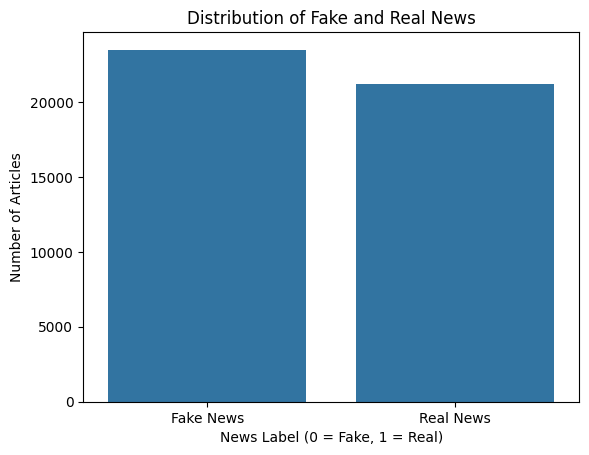

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label")

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Label (0 = Fake, 1 = Real)")
plt.ylabel("Number of Articles")
plt.xticks([0, 1], ["Fake News", "Real News"])
plt.show()

In [34]:
# Calculate the number of words in each article
df["word_count"] = df["text"].apply(
    lambda text: len(text.split())
)

# Display the result
display(df[["text", "label", "word_count"]].head())

,text,label,word_count
0,WASHINGTON (Reuters) - The head of a conservat...,1,749
1,WASHINGTON (Reuters) - Transgender people will...,1,624
2,WASHINGTON (Reuters) - The special counsel inv...,1,457
3,WASHINGTON (Reuters) - Trump campaign adviser ...,1,376
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,1,852


In [35]:
df.groupby("label")["word_count"].mean()

,word_count
label,
0,423.224167
1,384.757484


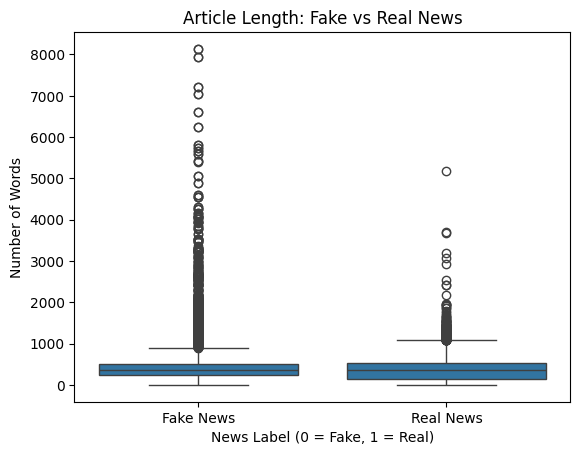

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df, x="label", y="word_count")

plt.title("Article Length: Fake vs Real News")
plt.xlabel("News Label (0 = Fake, 1 = Real)")
plt.ylabel("Number of Words")
plt.xticks([0, 1], ["Fake News", "Real News"])
plt.show()

linguistic feature extraction


In [37]:
import re

df["sentence_count"] = df["text"].apply(
    lambda text: len(
        [s for s in re.split(r'[.!?]+', text) if s.strip()]
    )
)

display(df[["text", "sentence_count"]].head())

,text,sentence_count
0,WASHINGTON (Reuters) - The head of a conservat...,42
1,WASHINGTON (Reuters) - Transgender people will...,37
2,WASHINGTON (Reuters) - The special counsel inv...,22
3,WASHINGTON (Reuters) - Trump campaign adviser ...,21
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,60


In [38]:
df["avg_word_length"] = df["text"].apply(
    lambda text: (
        sum(len(word) for word in text.split()) /
        len(text.split())
        if len(text.split()) > 0 else 0
    )
)

display(df[["text", "avg_word_length"]].head())

,text,avg_word_length
0,WASHINGTON (Reuters) - The head of a conservat...,5.216288
1,WASHINGTON (Reuters) - Transgender people will...,5.533654
2,WASHINGTON (Reuters) - The special counsel inv...,5.085339
3,WASHINGTON (Reuters) - Trump campaign adviser ...,5.545213
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,5.095070


In [39]:
import string

df["punctuation_count"] = df["text"].apply(
    lambda text: sum(
        1 for char in text if char in string.punctuation
    )
)

display(df[["text", "punctuation_count"]].head())

,text,punctuation_count
0,WASHINGTON (Reuters) - The head of a conservat...,118
1,WASHINGTON (Reuters) - Transgender people will...,77
2,WASHINGTON (Reuters) - The special counsel inv...,47
3,WASHINGTON (Reuters) - Trump campaign adviser ...,51
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,136


In [40]:
df.groupby("label")[
    ["word_count", "sentence_count",
     "avg_word_length", "punctuation_count"]
].mean().round(2)

,word_count,sentence_count,avg_word_length,punctuation_count
label,,,,
0,423.22,23.46,5.01,59.08
1,384.76,20.88,5.18,50.53


In [41]:
df["capital_letter_count"] = df["text"].apply(
    lambda text: sum(1 for char in text if char.isupper())
)

display(df[["text", "capital_letter_count"]].head())

,text,capital_letter_count
0,WASHINGTON (Reuters) - The head of a conservat...,155
1,WASHINGTON (Reuters) - Transgender people will...,119
2,WASHINGTON (Reuters) - The special counsel inv...,117
3,WASHINGTON (Reuters) - Trump campaign adviser ...,110
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,200


In [42]:
df["unique_word_count"] = df["text"].apply(
    lambda text: len(set(text.lower().split()))
)

display(df[["text", "unique_word_count"]].head())

,text,unique_word_count
0,WASHINGTON (Reuters) - The head of a conservat...,414
1,WASHINGTON (Reuters) - Transgender people will...,329
2,WASHINGTON (Reuters) - The special counsel inv...,247
3,WASHINGTON (Reuters) - Trump campaign adviser ...,230
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,430


In [43]:
df.groupby("label")[
    [
        "capital_letter_count",
        "unique_word_count",
        "word_count"
    ]
].mean().round(2)

,capital_letter_count,unique_word_count,word_count
label,,,
0,103.35,232.38,423.22
1,87.35,220.18,384.76


NLP Text preprocessing

In [44]:
df["cleaned_text"] = df["text"].astype(str).str.lower()

display(df[["text", "cleaned_text"]].head())

,text,cleaned_text
0,WASHINGTON (Reuters) - The head of a conservat...,washington (reuters) - the head of a conservat...
1,WASHINGTON (Reuters) - Transgender people will...,washington (reuters) - transgender people will...
2,WASHINGTON (Reuters) - The special counsel inv...,washington (reuters) - the special counsel inv...
3,WASHINGTON (Reuters) - Trump campaign adviser ...,washington (reuters) - trump campaign adviser ...
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,seattle/washington (reuters) - president donal...


In [45]:
print("Original text:")
print(df["text"].iloc[0][:300])

print("\nCleaned text:")
print(df["cleaned_text"].iloc[0][:300])

Original text:
WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged budget restraint in 2018. In keeping with a sharp pivot under way 

Cleaned text:
washington (reuters) - the head of a conservative republican faction in the u.s. congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on sunday and urged budget restraint in 2018. in keeping with a sharp pivot under way 


In [46]:
import re

def remove_urls(text):
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    return text

df["cleaned_text"] = df["cleaned_text"].apply(remove_urls)

In [47]:
print("Original text:")
print(df["text"].iloc[0][:300])

print("\nCleaned text:")
print(df["cleaned_text"].iloc[0][:300])

Original text:
WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged budget restraint in 2018. In keeping with a sharp pivot under way 

Cleaned text:
washington (reuters) - the head of a conservative republican faction in the u.s. congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on sunday and urged budget restraint in 2018. in keeping with a sharp pivot under way 


In [48]:
import re

def clean_text(text):
    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Keep letters, numbers and spaces
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["cleaned_text"] = df["cleaned_text"].apply(clean_text)

In [49]:
print("Original article:")
print(df["text"].iloc[0][:300])

print("\nCleaned article:")
print(df["cleaned_text"].iloc[0][:300])

Original article:
WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged budget restraint in 2018. In keeping with a sharp pivot under way 

Cleaned article:
washington reuters the head of a conservative republican faction in the u s congress who voted this month for a huge expansion of the national debt to pay for tax cuts called himself a fiscal conservative on sunday and urged budget restraint in 2018 in keeping with a sharp pivot under way among repu


Tokenization

In [50]:
!pip install nltk

In [51]:
import nltk
from nltk.tokenize import wordpunct_tokenize

In [52]:
df["tokens"] = df["cleaned_text"].apply(wordpunct_tokenize)

display(df[["cleaned_text", "tokens"]].head())

,cleaned_text,tokens
0,washington reuters the head of a conservative ...,"[washington, reuters, the, head, of, a, conser..."
1,washington reuters transgender people will be ...,"[washington, reuters, transgender, people, wil..."
2,washington reuters the special counsel investi...,"[washington, reuters, the, special, counsel, i..."
3,washington reuters trump campaign adviser geor...,"[washington, reuters, trump, campaign, adviser..."
4,seattle washington reuters president donald tr...,"[seattle, washington, reuters, president, dona..."


In [53]:
print(df["tokens"].iloc[0][:30])

['washington', 'reuters', 'the', 'head', 'of', 'a', 'conservative', 'republican', 'faction', 'in', 'the', 'u', 's', 'congress', 'who', 'voted', 'this', 'month', 'for', 'a', 'huge', 'expansion', 'of', 'the', 'national', 'debt', 'to', 'pay', 'for', 'tax']


Stopwords are common words such as is, the, a, an, and of remove it

In [54]:
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

print("Number of English stopwords:", len(stop_words))

Number of English stopwords: 198


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [55]:
df["filtered_tokens"] = df["tokens"].apply(
    lambda tokens: [
        word for word in tokens
        if word.lower() not in stop_words
    ]
)

display(df[["tokens", "filtered_tokens"]].head())

,tokens,filtered_tokens
0,"[washington, reuters, the, head, of, a, conser...","[washington, reuters, head, conservative, repu..."
1,"[washington, reuters, transgender, people, wil...","[washington, reuters, transgender, people, all..."
2,"[washington, reuters, the, special, counsel, i...","[washington, reuters, special, counsel, invest..."
3,"[washington, reuters, trump, campaign, adviser...","[washington, reuters, trump, campaign, adviser..."
4,"[seattle, washington, reuters, president, dona...","[seattle, washington, reuters, president, dona..."


In [56]:
df["processed_text"] = df["filtered_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

display(df[["cleaned_text", "processed_text"]].head())

,cleaned_text,processed_text
0,washington reuters the head of a conservative ...,washington reuters head conservative republica...
1,washington reuters transgender people will be ...,washington reuters transgender people allowed ...
2,washington reuters the special counsel investi...,washington reuters special counsel investigati...
3,washington reuters trump campaign adviser geor...,washington reuters trump campaign adviser geor...
4,seattle washington reuters president donald tr...,seattle washington reuters president donald tr...


Lemmatization converts words into their meaningful base forms.
Original word	Lemmatized word
running	-run
studies -	study

In [57]:
!pip install nltk

In [58]:
import nltk

nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger_eng")

from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

lemmatizer = WordNetLemmatizer()

print(lemmatizer.lemmatize("cars"))
print(lemmatizer.lemmatize("running", pos="v"))
print(lemmatizer.lemmatize("studies", pos="v"))

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


car
run
study


In [59]:
def lemmatize_tokens(tokens):
    return [
        lemmatizer.lemmatize(word, pos="v")
        for word in tokens
    ]

df["lemmatized_tokens"] = df["filtered_tokens"].apply(
    lemmatize_tokens
)

display(
    df[["filtered_tokens", "lemmatized_tokens"]].head()
)

,filtered_tokens,lemmatized_tokens
0,"[washington, reuters, head, conservative, repu...","[washington, reuters, head, conservative, repu..."
1,"[washington, reuters, transgender, people, all...","[washington, reuters, transgender, people, all..."
2,"[washington, reuters, special, counsel, invest...","[washington, reuters, special, counsel, invest..."
3,"[washington, reuters, trump, campaign, adviser...","[washington, reuters, trump, campaign, adviser..."
4,"[seattle, washington, reuters, president, dona...","[seattle, washington, reuters, president, dona..."


In [60]:
df["processed_text"] = df["lemmatized_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

display(df[["text", "processed_text"]].head())e

,text,processed_text
0,WASHINGTON (Reuters) - The head of a conservat...,washington reuters head conservative republica...
1,WASHINGTON (Reuters) - Transgender people will...,washington reuters transgender people allow fi...
2,WASHINGTON (Reuters) - The special counsel inv...,washington reuters special counsel investigati...
3,WASHINGTON (Reuters) - Trump campaign adviser ...,washington reuters trump campaign adviser geor...
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,seattle washington reuters president donald tr...
